<a href="https://colab.research.google.com/github/Zach-Kaplan44/Econ_5200_PS3/blob/main/ProblemSetPath3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.

## Setup

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [2]:
import io
import re
import urllib.request
import zipfile

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))

# public.dat is fixed-width numbers; the codebook supplies a name for each column
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

# Full-time-equivalent employment, Card & Krueger's outcome: full-timers, managers and
# half of part-timers, in each wave (a 2 at the end of a name marks the second wave)
ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

means_by_state = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()
nj, pa = means_by_state.loc[1], means_by_state.loc[0]    # STATE is 1 for New Jersey, 0 for Pennsylvania

did = (nj.fte_after - nj.fte_before) - (pa.fte_after - pa.fte_before)

print(f"{'':<12}{'before':>9}{'after':>9}{'change':>9}")
print("-" * 39)
print(f"{'NJ (treated)':<12}{nj.fte_before:>9.2f}{nj.fte_after:>9.2f}"
      f"{nj.fte_after - nj.fte_before:>9.2f}")
print(f"{'PA (control)':<12}{pa.fte_before:>9.2f}{pa.fte_after:>9.2f}"
      f"{pa.fte_after - pa.fte_before:>9.2f}")
print("-" * 39)
print(f"{'DiD':<12}{'':>18}{did:>9.2f}")

print(f"{len(ck)} restaurants: {int((ck.STATE == 1).sum())} NJ, "
      f"{int((ck.STATE == 0).sum())} PA")

               before    after   change
---------------------------------------
NJ (treated)    20.44    21.03     0.59
PA (control)    23.33    21.17    -2.17
---------------------------------------
DiD                                2.75
410 restaurants: 331 NJ, 79 PA


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [3]:
ck_long = ck.melt(
    id_vars=['SHEET', 'STATE'],
    value_vars=['fte_before', 'fte_after'],
    var_name ='wave', value_name='fte'
)
ck_long['post'] = (ck_long['wave'] == 'fte_after').astype(int)
ck_long = ck_long.dropna(subset=['fte'])
fit_ck = smf.ols("fte ~ STATE * post", data=ck_long).fit()

print(fit_ck.params.round(3))
print(f"2x2 by hand {did:.3f} | interaction {fit_ck.params['STATE:post']:.3f}")
print(f"state = the gap at the first wave: {means_by_state.loc[1, 'fte_before'] - means_by_state.loc[0, 'fte_before']:.3f}")
print(f"post = the change in PA from wave 1 to 2: {means_by_state.loc[0, 'fte_after'] - means_by_state.loc[0, 'fte_before']}")

Intercept     23.331
STATE         -2.892
post          -2.166
STATE:post     2.754
dtype: float64
2x2 by hand 2.754 | interaction 2.754
state = the gap at the first wave: -2.892
post = the change in PA from wave 1 to 2: -2.1655844155844157


*Your answer here.*

The first coefficient, -2.892 is the mean group difference in full time employees between NJ and PA in the pre-policy phase. The second coefficient, -2.166 is the mean group difference in full time employees between NJ and PA post-treatment. They are not causal quantities because they only show the gap between the states in each wave, they don't provide any information about how the states changed over time.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [4]:
# 40 Counties, 8 regional workforce boards with 5 counties per board
# adoption at the board level, all 5 counties in a board adopt in the same year
# 12 total periods, every board has a pre-treatment period
# boards adopt in different years across 4 years, at least one board never adopts
# treatment effect grows with exposure
# board-level shock that's shared by all counties within a board each year

never = 10**9
board_start = {0: 5, 1: 5, 2: 6, 3: 6, 4: 7, 5: 7, 6: 8, 7: never}
counties_per_board = 5
years = 12
job_growth = 0.5

rows = []
for board, g in board_start.items():
  shock = rng.normal(0, 0.3, years)
  for k in range(counties_per_board):
    county = f"b{board}c{k}"
    own = rng.normal(0, 2)
    for t in range(years):
      effect = job_growth * (t - g + 1) if t >= g else 0.0
      emp_rate = 60 + own + 0.2 * t + shock[t] + effect + rng.normal(0, 0.5)
      rows.append((county, board, g, t, int(t >= g), shock[t], effect, emp_rate))

counties = pd.DataFrame (rows, columns=['county', 'board', 'g', 't', 'D',
                                        'board_shock', 'true_eff', 'emp_rate'])
true_eff_counties = counties.loc[counties['D'] == 1, 'true_eff'].mean()

twfe_counties = smf.ols("emp_rate ~ D + C(county) + C(t)", data=counties).fit()

print(f"{counties['county'].nunique()} counties in {counties['board'].nunique()} boards, {years} years")
print(f"TWFE {twfe_counties.params['D']:.3f} percentage points | true average effect on treated {true_eff_counties:.3f} percentage points")



40 counties in 8 boards, 12 years
TWFE 0.653 percentage points | true average effect on treated 1.725 percentage points


*Your answer here.*

The true effect of the training program is a mean additional increase in employment rate of 1.725 percentage points per year. The TWFE regression reports that the training program gives a mean additional increase in employment rate of 0.653 percentage points per year.

### Step 2.2: Decompose it (15 pts)

In [5]:
cohort_means = counties.groupby(['g', 't'])['emp_rate'].mean().unstack()
counties_per_cohort = counties.groupby('g')['county'].nunique()

def two_by_two_cohorts(cohort_means, counties_per_cohort, n_periods, treated_adopt, control_adopt, before_years, after_years):
  treated_means, control_means = cohort_means.loc[treated_adopt], cohort_means.loc[control_adopt]
  estimate = ((treated_means[after_years].mean() - treated_means[before_years].mean()) -
                      (control_means[after_years].mean() - control_means[before_years].mean()))
  n_total = counties_per_cohort.sum()           # all counties in this panel
  n_treated = counties_per_cohort[treated_adopt]
  n_control = counties_per_cohort[control_adopt]
  window_years = len(before_years) + len(after_years)

  pair_share = (n_treated + n_control) / n_total      # share of total counties in this comparison's cohorts
  window_share = window_years / n_periods             # share of all periods in this comparison
  p = n_treated / (n_treated + n_control)             # share of counties in this comparison that are in the treated cohort
  d = len(after_years) / window_years                 # share of years in the window where the treated cohort is treated

  weight = (pair_share * window_share) ** 2 * p * (1-p) * d * (1-d)



  return estimate, weight

comparisons = []

for year in [5, 6, 7, 8]:
  estimate, weight = two_by_two_cohorts(cohort_means, counties_per_cohort, 12, year, never, range(0, year), range(year, 12))
  comparisons.append({'treated': year, 'control': never, 'kind': 'vs never', 'estimate': estimate, 'weight': weight})



for treated in [5 , 6, 7 , 8]:
  for control in [5, 6, 7, 8]:
    if treated == control:
      continue

    if treated < control:
      kind = 'clean'
      before = range(0, treated)
      after = range(treated, control)

    else:
      kind = 'forbidden'
      before = range(control, treated)
      after = range(treated, 12)
    estimate, weight = two_by_two_cohorts(cohort_means, counties_per_cohort, 12, treated, control, before, after)
    comparisons.append({'treated': treated, 'control': control, 'kind': kind, 'estimate': estimate, 'weight': weight})


decomposition = pd.DataFrame(comparisons)
decomposition['weight'] = decomposition['weight']/decomposition['weight'].sum()

weighted_sum = (decomposition['estimate'] * decomposition['weight']).sum()
forbidden_share = decomposition.loc[decomposition['kind'] == 'forbidden', 'weight'].sum()

true_min = counties.loc[counties['D'] == 1, 'true_eff'].min()
true_max = counties.loc[counties['D'] == 1, 'true_eff'].max()

print(decomposition)
print(decomposition['weight'].sum())
print(len(decomposition))
print(f"Weighted sum of 2x2s: {weighted_sum:.6f} | TWFE coefficient: {twfe_counties.params['D']:.6f}")
print(f"Share of TWFE weight coming from forbidden comparisons: {forbidden_share:.1%}")
print(f"Maximum true effect across all treated county-years: {true_max:.3f}")
print(f"Minimum true effect across all treated county-years: {true_min:.3f}")


    treated     control       kind  estimate  weight
0         5  1000000000   vs never     1.845   0.133
1         6  1000000000   vs never     1.427   0.136
2         7  1000000000   vs never     1.028   0.133
3         8  1000000000   vs never     1.017   0.061
4         5           6      clean     0.981   0.038
5         5           7      clean     0.736   0.076
6         5           8      clean     0.190   0.057
7         6           5  forbidden     0.235   0.045
8         6           7      clean     0.282   0.045
9         6           8      clean     0.425   0.045
10        7           5  forbidden    -0.662   0.076
11        7           6  forbidden    -0.407   0.038
12        7           8      clean     0.611   0.027
13        8           5  forbidden    -1.355   0.045
14        8           6  forbidden    -0.702   0.030
15        8           7  forbidden     0.125   0.015
1.0
16
Weighted sum of 2x2s: 0.653329 | TWFE coefficient: 0.653329
Share of TWFE weight coming from

*Your answer here.*
As can be seen above, while the overall TWFE still lies within the range of true effects, it is incredibly close to the minimum. Every estimate coming from a forbidden comparison is either negative, or positive, small and under the range of true effects. The one never-treated board causes the overall TWFE estimate to still fall inside the range of true effects, but it is clear that the forbidden comparisons pull it significantly downwards.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [6]:
def clean_att(df):
    """ATT(g, t) cells against not-yet-treated controls, and their size-weighted average."""
    out = []
    for g in sorted(df.loc[df["g"] < never, "g"].unique()):
        treated = df[df["g"] == g]
        for t in range(g, df["t"].max() + 1):
            controls = df[df["g"] > t]
            if controls.empty:
                continue
            d_tr = (treated.loc[treated["t"] == t, "emp_rate"].mean()
                    - treated.loc[treated["t"] == g - 1, "emp_rate"].mean())
            d_co = (controls.loc[controls["t"] == t, "emp_rate"].mean()
                    - controls.loc[controls["t"] == g - 1, "emp_rate"].mean())
            n = (treated["t"] == t).sum()
            out.append({"g": g, "t": t, "att": d_tr - d_co, "n": n})
    cells = pd.DataFrame(out)
    return cells, np.average(cells["att"], weights=cells["n"])

per_cell, att_hat = clean_att(counties)
display_cells = per_cell.rename(columns={
    "g": "Cohort adoption period",
    "t": "Year Measured",
    "att": "Estimated effect (pp)",
    "n": "Number of Treated Counties"
})

display(display_cells.round(3))
print(f"{'estimator':<38}{'estimate':>10}{'truth':>9}")
print("-" * 57)
print(f"{'TWFE (all comparisons)':<38}{twfe_counties.params['D']:>10.2f}{true_eff_counties:>9.2f}")
print(f"{'Not-yet-treated controls only':<38}{att_hat:>10.2f}{true_eff_counties:>9.2f}")



,Cohort adoption period,Year Measured,Estimated effect (pp),Number of Treated Counties
0,5,5,0.911,10
1,5,6,1.065,10
2,5,7,1.859,10
3,5,8,3.152,10
4,5,9,2.346,10
5,5,10,3.455,10
6,5,11,3.509,10
7,6,6,0.793,10
8,6,7,1.719,10
9,6,8,3.064,10


estimator                               estimate    truth
---------------------------------------------------------
TWFE (all comparisons)                      0.65     1.73
Not-yet-treated controls only               1.96     1.73


*Your answer here.* As can be seen above, when only using not yet treated cohorts as the control (either the never-treated cohort, or the cohort that adopts in a later period than the treated cohort) the TWFE estimate moves substantially closer to the true average effect, a gap of about 0.23 percentage points, as opposed to a gap of 1.08 percentage points when the forbidden comparison is included.

### Step 3.2: The assumption you cannot test (12 pts)

            -8    -7    -6    -5    -4    -3    -2   -1     0     1     2     3     4     5     6
estimate  0.11  0.14  0.51  0.64  0.54  0.73  0.54  0.0  0.56  0.94  1.72  2.08  2.58  3.09  4.11
truth     0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.0  0.50  1.00  1.50  2.00  2.50  3.00  3.50


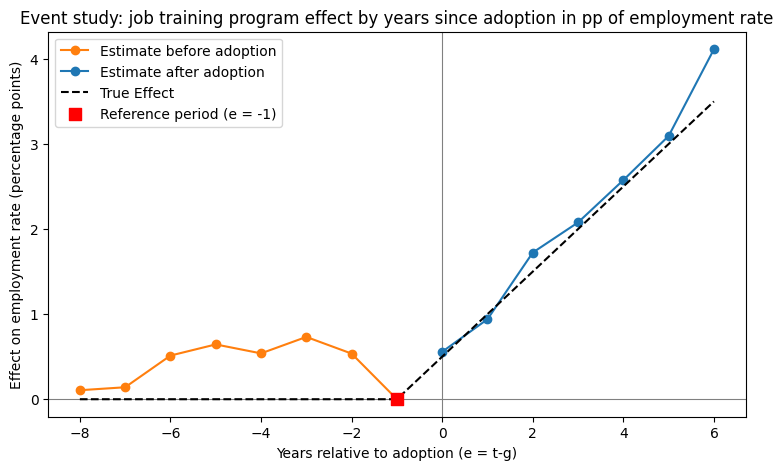

In [7]:
counties_study = counties.copy()
ref_year = -1
counties_study['e'] = np.where(counties_study['g'] < never, counties_study['t'] - counties_study['g'], np.nan)
event_times = sorted(int(e) for e in counties_study['e'].dropna().unique())

col = {}
for e in event_times:
  if e == ref_year:
    continue
  col[e] = f"pre{-e}" if e < 0 else f"post{e}"
  counties_study[col[e]] = (counties_study['e'] == e).astype(int)


es_fit_counties = smf.ols("emp_rate ~ " + "+".join(col.values()) + " + C(county) + C(t)", data=counties_study).fit()
es_counties = pd.Series({e: (0.0 if e == ref_year else es_fit_counties.params[col[e]]) for e in event_times})
truth_path = pd.Series({e: job_growth * (e + 1) if e >= 0 else 0.0 for e in event_times})

fig, ax = plt.subplots(figsize=(9, 5))

ax.axvline(0, color='gray', linewidth = 0.8)
ax.axhline(0, color='gray', linewidth = 0.8)

#splitting estimates into pre and post adoption
pre = es_counties[es_counties.index < 0]
post = es_counties[es_counties.index >= 0]

ax.plot(pre.index, pre.values, marker ='o', color='tab:orange', label='Estimate before adoption')
ax.plot(post.index, post.values, marker ='o', color='tab:blue', label='Estimate after adoption')

#plotting true path
ax.plot(truth_path.index, truth_path.values, linestyle="--", color='black', label='True Effect')
ax.scatter([ref_year], [0], marker='s', s=80, color='red', label=f"Reference period (e = {ref_year})", zorder=3)

#Plot labels and legends
ax.set_xlabel("Years relative to adoption (e = t-g)")
ax.set_ylabel("Effect on employment rate (percentage points)")
ax.set_title("Event study: job training program effect by years since adoption in pp of employment rate")
ax.legend()

print(pd.DataFrame({"estimate": es_counties, "truth": truth_path}).round(2).T.to_string())
plt.show()

*Your answer here.* The omitted year is e = -1, the year before each cohort adopts. Every point on the chart is the difference in estimate relative to that year, so the choice matters because it changes what you are comparing against.

A flat pre-trend estimate can establish that there was some change in the estimate after adoption. However, what it cannot imply is that this estimate is a causal trend. Because this estimate is conditional on the board being selected for the program, it is would be necessary to know if there is any sort of characteristics across some or all boards that are correlated with both selection into the program, and job growth. It would also be necessary to know if boards may have anticipated shocks in the job market ahead of time which lead to entrance into the program. Finally, on the subject of shocks, it is necessary to know if shocks to the job market occured around the same time as adoption, as this would contaminate the post-adoption trend, and also to know whether there were nationwide trends in the job market that would match the trend in the post-adoption window.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

In [8]:
f_counties = "emp_rate ~ D + C(county) + C(t)"
fits_counties = {
    "default (iid)": smf.ols(f_counties, data = counties).fit(),
    "clustered by county": smf.ols(f_counties, data=counties).fit(cov_type="cluster",
                                                                  cov_kwds={"groups": counties["county"]}),
    "clustered by board": smf.ols(f_counties, data=counties).fit(cov_type="cluster",
                                                                 cov_kwds={"groups": counties["board"]})
}

print(f"{'':<22}{'estimate':>9}{'std err':>9}{'p':>9}{'clusters':>10}")
for label, f in fits_counties.items():
  n_cl = getattr(f, "n_groups", "none")
  print(f"{label:<22}{f.params['D']:>9.3f}{f.bse['D']:>9.3f}{f.pvalues['D']:>9.3f}{n_cl:>10}")

                       estimate  std err        p  clusters
default (iid)             0.653    0.129    0.000      none
clustered by county       0.653    0.210    0.002        40
clustered by board        0.653    0.431    0.130         8


The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [9]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit (ECON 5200 PS3), extending Lab 11's did_utils.py."""
from __future__ import annotations
from typing import Dict

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

NEVER = 10**9

# Lab 11's functions, carried over
def two_by_two(df: pd.DataFrame, outcome: str, treated: str, post: str) -> float:
    """The canonical 2x2: difference of differences of the four group means."""
    g = df.groupby([treated, post])[outcome].mean()
    return (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])


def att_by_cohort_period(df: pd.DataFrame, time: str, outcome: str,
                         cohort: str) -> pd.DataFrame:
    """ATT(g, t) for every cohort g and period t >= g.

    Controls are units NOT YET treated at t, never units already treated.
    The baseline is period g - 1, the last period before cohort g is treated.
    Returns one row per (g, t): the event time e = t - g, the estimate, and
    the number of treated units it rests on.
    """
    out = []
    cohorts = sorted(c for c in df[cohort].unique() if c < NEVER)
    for g in cohorts:
        tr = df[df[cohort] == g]
        for t in sorted(df.loc[df[time] >= g, time].unique()):
            co = df[df[cohort] > t]              # not yet treated at t
            if co.empty or (tr[time] == g - 1).sum() == 0:
                continue                         # no control left, or no baseline period
            d_tr = (tr.loc[tr[time] == t, outcome].mean()
                    - tr.loc[tr[time] == g - 1, outcome].mean())
            d_co = (co.loc[co[time] == t, outcome].mean()
                    - co.loc[co[time] == g - 1, outcome].mean())
            out.append({"g": g, "t": t, "e": t - g,
                        "att": d_tr - d_co, "n": int((tr[time] == t).sum())})
    return pd.DataFrame(out)


def overall_att(cells: pd.DataFrame) -> float:
    """Size-weighted average of the ATT(g, t) cells."""
    return float(np.average(cells["att"], weights=cells["n"]))


def event_study(cells: pd.DataFrame) -> pd.DataFrame:
    """Average the ATT(g, t) cells by event time e = t - g, weighted by size.

    Negative e would be pre-treatment periods. They are a diagnostic, not a
    test: estimates near zero are consistent with parallel trends and do not
    establish it.
    """
    rows = []
    for e, group in cells.groupby("e"):
        rows.append({"e": e, "att": np.average(group["att"], weights=group["n"])})
    return pd.DataFrame(rows)


def cluster_se_ratio(fit_iid, fit_clustered, param: str) -> float:
    """How many times larger the clustered standard error is than the iid one."""
    return float(fit_clustered.bse[param] / fit_iid.bse[param])

def clean_att(df: pd.DataFrame, outcome: str, cohort: str = 'g', time: str = 't', never: int = 10**9) -> tuple [pd.DataFrame, float]:
  """ATT(g, t) cells against not-yet-treated controls, and their size-weighted average
      Each cell compares cohort g's change from period g - 1 to period t with the same
      change for every unit not yet treated at t. Returns a DF with one row per cell (g, t, att, n)
      and the n-weighted average of att.
  """

  out = []
  for g in sorted(df.loc[df[cohort] < never, cohort].unique()):
    treated = df[df[cohort] == g]
    for t in range(g, df[time].max() + 1):
      controls = df[df[cohort] > t]
      if controls.empty:
        continue
      d_tr = (treated.loc[treated[time] == t, outcome].mean()
              - treated.loc[treated[time] == g - 1, outcome].mean())
      d_co = (controls.loc[controls[time] == t, outcome].mean()
            - controls.loc[controls[time] == g -1, outcome].mean())
      n = (treated[time] == t).sum()
      out.append({"g": g, "t": t, "att": d_tr - d_co, "n": n})
    cells = pd.DataFrame(out)
  return cells, float(np.average(cells['att'], weights=cells['n']))
# your clustered-inference wrapper (Step 3.3)


def clustered_fits(df: pd.DataFrame, formula: str, param: str, clusters: dict[str, str]) -> pd.DataFrame:

  rows = []
  fit = smf.ols(formula, data=df).fit()
  rows.append({"fit": "default(iid)", "estimate": fit.params[param],
               "std_err": fit.bse[param], "p_value": fit.pvalues[param],
               "n_clusters": None})
  for label, column in clusters.items():
    fit = smf.ols(formula, data=df).fit(cov_type="cluster",
                                        cov_kwds={"groups": df[column]})
    rows.append({"fit": f"clustered by {label}", "estimate": fit.params[param],
                "std_err": fit.bse[param], "p_value": fit.pvalues[param]})
  return pd.DataFrame(rows)


# your bootstrap (Task 4.1)
"""Inference tools for difference-in-differences panels with few clusters."""




def wild_cluster_bootstrap_did(
    data: pd.DataFrame,
    outcome: str,
    treatment: str,
    unit: str,
    time: str,
    cluster: str,
    tol: float = 1e-10,
) -> Dict[str, float]:
    """Wild cluster bootstrap-t for the treatment coefficient of a two-way DiD.

    Fits ``outcome ~ treatment + C(unit) + C(time)`` with cluster-robust
    standard errors, then tests H0: beta_treatment = 0 by the restricted
    ("null-imposed") wild cluster bootstrap of Cameron, Gelbach and Miller
    (2008). Rademacher weights are drawn once per cluster and *all* 2**G
    weight vectors are enumerated, so the bootstrap distribution is exact
    rather than simulated.

    Parameters
    ----------
    data:
        Long panel, one row per unit-period.
    outcome:
        Column name of the dependent variable.
    treatment:
        Column name of the treatment indicator whose coefficient is tested.
    unit:
        Column name of the cross-sectional identifier (absorbed as fixed
        effects).
    time:
        Column name of the period identifier (absorbed as fixed effects).
    cluster:
        Column name of the level at which treatment is assigned and errors
        are clustered.
    tol:
        Absolute tolerance used when comparing ``|t*|`` to ``|t|``, so that
        the all-positive weight vector -- which reproduces the actual data
        exactly in theory -- is not excluded by floating-point noise.

    Returns
    -------
    dict
        ``coef``, ``se`` and ``t`` for the treatment coefficient from the
        unrestricted cluster-robust fit; ``p_naive``, the cluster-robust
        p-value statsmodels reports for it; ``p_bootstrap``, the share of
        enumerated ``|t*|`` at least as large as ``|t|``; ``n_clusters``;
        ``n_replications`` (= 2**n_clusters); and ``min_p_attainable``, the
        smallest p-value the enumeration can produce.

    Raises
    ------
    ValueError
        If a required column is missing, if the cluster count is outside the
        range where full enumeration is feasible, or if treatment is not
        constant within cluster-period cells in a way that leaves it
        collinear with the fixed effects.
    """
    required = [outcome, treatment, unit, time, cluster]
    missing = [c for c in required if c not in data.columns]
    if missing:
        raise ValueError(f"missing column(s): {missing}")

    df = data.loc[:, required].dropna().reset_index(drop=True)
    if df.empty:
        raise ValueError("no complete rows after dropping missing values")

    codes, _ = pd.factorize(df[cluster], sort=True)
    codes = np.asarray(codes, dtype=int)
    n_clusters = int(codes.max()) + 1
    if not 2 <= n_clusters <= 20:
        raise ValueError(
            f"full enumeration needs between 2 and 20 clusters; got "
            f"{n_clusters} (2**{n_clusters} weight vectors)"
        )
    groups = codes

    fe = f"C({unit}) + C({time})"
    unrestricted_formula = f"{outcome} ~ {treatment} + {fe}"
    restricted_formula = f"{outcome} ~ {fe}"

    # Unrestricted model: design matrix is reused for every bootstrap fit.
    model = smf.ols(unrestricted_formula, data=df)
    exog = np.asarray(model.exog, dtype=float)
    try:
        k_treat = list(model.exog_names).index(treatment)
    except ValueError as err:  # pragma: no cover - defensive
        raise ValueError(f"{treatment!r} not in the design matrix") from err

    cov_kwds = {"groups": groups}
    actual = model.fit(cov_type="cluster", cov_kwds=cov_kwds)
    coef = float(actual.params.iloc[k_treat])
    se = float(actual.bse.iloc[k_treat])
    t_actual = float(actual.tvalues.iloc[k_treat])
    p_naive = float(actual.pvalues.iloc[k_treat])
    if not np.isfinite(t_actual):
        raise ValueError(
            f"{treatment!r} is collinear with the {unit}/{time} fixed effects"
        )

    # Step 1: restricted fit -- the treatment coefficient forced to zero.
    restricted = smf.ols(restricted_formula, data=df).fit()
    y_tilde = np.asarray(restricted.fittedvalues, dtype=float)
    u_tilde = np.asarray(restricted.resid, dtype=float)

    # Step 2: all 2**G Rademacher vectors, one weight per cluster, expanded
    # to one weight per observation via the cluster map.
    draws = np.arange(2**n_clusters)
    signs = 1.0 - 2.0 * ((draws[:, None] >> np.arange(n_clusters)) & 1)
    weights = signs[:, codes]

    t_star = np.empty(len(draws), dtype=float)
    for r in range(len(draws)):
        # Step 3: synthetic outcome under the null.
        y_star = y_tilde + weights[r] * u_tilde
        # Step 4: re-estimate the unrestricted model, keep the clustered t.
        fit = sm.OLS(y_star, exog).fit(cov_type="cluster", cov_kwds=cov_kwds)
        t_star[r] = fit.tvalues[k_treat]

    # Step 5: symmetric (two-sided) bootstrap p-value.
    p_bootstrap = float(
        np.mean(np.abs(t_star) >= np.abs(t_actual) - tol)
    )

    return {
        "coef": coef,
        "se": se,
        "t": t_actual,
        "p_naive": p_naive,
        "p_bootstrap": p_bootstrap,
        "n_clusters": float(n_clusters),
        "n_replications": float(len(draws)),
        "min_p_attainable": 2.0 / len(draws),
    }

if __name__ == "__main__":
    ...   # passing assertions

Overwriting src/did_toolkit.py


In [10]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
from src import did_toolkit as dt
# prove it runs: call each function on your panel
print(dt.two_by_two(ck_long,'fte', 'STATE', 'post'))
cells_mod = dt.att_by_cohort_period(counties, "t", "emp_rate", "g")
print(cells_mod)
print(dt.overall_att(cells_mod))
print(dt.event_study(cells_mod))
print(dt.cluster_se_ratio(fits_counties["default (iid)"], fits_counties["clustered by board"], "D"))
cells_clean, att_mod = dt.clean_att(counties, "emp_rate")
print(cells_clean)
print(att_mod)
print(dt.clustered_fits(counties, f_counties, "D", {"county": "county", "board": "board"}))
print(dt.wild_cluster_bootstrap_did(counties, "emp_rate", "D", "county", "t", "board"))

2.753605782980582
    g   t  e    att   n
0   5   5  0  0.911  10
1   5   6  1  1.065  10
2   5   7  2  1.859  10
3   5   8  3  3.152  10
4   5   9  4  2.346  10
5   5  10  5  3.455  10
6   5  11  6  3.509  10
7   6   6  0  0.793  10
8   6   7  1  1.719  10
9   6   8  2  3.064  10
10  6   9  3  1.832  10
11  6  10  4  2.889  10
12  6  11  5  2.349  10
13  7   7  0  0.425  10
14  7   8  1  1.694  10
15  7   9  2  1.015  10
16  7  10  3  1.909  10
17  7  11  4  1.514  10
18  8   8  0  2.293   5
19  8   9  1  1.066   5
20  8  10  2  2.213   5
21  8  11  3  1.955   5
1.9630332362061773
   e    att
0  0  0.936
1  1  1.431
2  2  2.013
3  3  2.248
4  4  2.249
5  5  2.902
6  6  3.509
3.340656835251453
    g   t    att   n
0   5   5  0.911  10
1   5   6  1.065  10
2   5   7  1.859  10
3   5   8  3.152  10
4   5   9  2.346  10
5   5  10  3.455  10
6   5  11  3.509  10
7   6   6  0.793  10
8   6   7  1.719  10
9   6   8  3.064  10
10  6   9  1.832  10
11  6  10  2.889  10
12  6  11  2.349  10
13 

*Your answer here.* The board clustering is the correct level. Doing iid treats every single county-year pair as independent, and clustering by county treats every county as independent. Because treatment was applied at the board level, the clustering must stay at that level so you are not treating correlated outcomes as independent.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [11]:
#counties[['county', 'board', 'g', 't', 'D', 'emp_rate']].to_csv('counties_panel.csv', index=False)

#from google.colab import files
#files.download('counties_panel.csv')

"""Inference tools for difference-in-differences panels with few clusters."""

from typing import Dict

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf


def wild_cluster_bootstrap_did(
    data: pd.DataFrame,
    outcome: str,
    treatment: str,
    unit: str,
    time: str,
    cluster: str,
    tol: float = 1e-10,
) -> Dict[str, float]:
    """Wild cluster bootstrap-t for the treatment coefficient of a two-way DiD.

    Fits ``outcome ~ treatment + C(unit) + C(time)`` with cluster-robust
    standard errors, then tests H0: beta_treatment = 0 by the restricted
    ("null-imposed") wild cluster bootstrap of Cameron, Gelbach and Miller
    (2008). Rademacher weights are drawn once per cluster and *all* 2**G
    weight vectors are enumerated, so the bootstrap distribution is exact
    rather than simulated.

    Parameters
    ----------
    data:
        Long panel, one row per unit-period.
    outcome:
        Column name of the dependent variable.
    treatment:
        Column name of the treatment indicator whose coefficient is tested.
    unit:
        Column name of the cross-sectional identifier (absorbed as fixed
        effects).
    time:
        Column name of the period identifier (absorbed as fixed effects).
    cluster:
        Column name of the level at which treatment is assigned and errors
        are clustered.
    tol:
        Absolute tolerance used when comparing ``|t*|`` to ``|t|``, so that
        the all-positive weight vector -- which reproduces the actual data
        exactly in theory -- is not excluded by floating-point noise.

    Returns
    -------
    dict
        ``coef``, ``se`` and ``t`` for the treatment coefficient from the
        unrestricted cluster-robust fit; ``p_naive``, the cluster-robust
        p-value statsmodels reports for it; ``p_bootstrap``, the share of
        enumerated ``|t*|`` at least as large as ``|t|``; ``n_clusters``;
        ``n_replications`` (= 2**n_clusters); and ``min_p_attainable``, the
        smallest p-value the enumeration can produce.

    Raises
    ------
    ValueError
        If a required column is missing, if the cluster count is outside the
        range where full enumeration is feasible, or if treatment is not
        constant within cluster-period cells in a way that leaves it
        collinear with the fixed effects.
    """
    required = [outcome, treatment, unit, time, cluster]
    missing = [c for c in required if c not in data.columns]
    if missing:
        raise ValueError(f"missing column(s): {missing}")

    df = data.loc[:, required].dropna().reset_index(drop=True)
    if df.empty:
        raise ValueError("no complete rows after dropping missing values")

    codes, _ = pd.factorize(df[cluster], sort=True)
    codes = np.asarray(codes, dtype=int)
    n_clusters = int(codes.max()) + 1
    if not 2 <= n_clusters <= 20:
        raise ValueError(
            f"full enumeration needs between 2 and 20 clusters; got "
            f"{n_clusters} (2**{n_clusters} weight vectors)"
        )
    groups = codes

    fe = f"C({unit}) + C({time})"
    unrestricted_formula = f"{outcome} ~ {treatment} + {fe}"
    restricted_formula = f"{outcome} ~ {fe}"

    # Unrestricted model: design matrix is reused for every bootstrap fit.
    model = smf.ols(unrestricted_formula, data=df)
    exog = np.asarray(model.exog, dtype=float)
    try:
        k_treat = list(model.exog_names).index(treatment)
    except ValueError as err:  # pragma: no cover - defensive
        raise ValueError(f"{treatment!r} not in the design matrix") from err

    cov_kwds = {"groups": groups}
    actual = model.fit(cov_type="cluster", cov_kwds=cov_kwds)
    coef = float(actual.params.iloc[k_treat])
    se = float(actual.bse.iloc[k_treat])
    t_actual = float(actual.tvalues.iloc[k_treat])
    p_naive = float(actual.pvalues.iloc[k_treat])
    if not np.isfinite(t_actual):
        raise ValueError(
            f"{treatment!r} is collinear with the {unit}/{time} fixed effects"
        )

    # Step 1: restricted fit -- the treatment coefficient forced to zero.
    restricted = smf.ols(restricted_formula, data=df).fit()
    y_tilde = np.asarray(restricted.fittedvalues, dtype=float)
    u_tilde = np.asarray(restricted.resid, dtype=float)

    # Step 2: all 2**G Rademacher vectors, one weight per cluster, expanded
    # to one weight per observation via the cluster map.
    draws = np.arange(2**n_clusters)
    signs = 1.0 - 2.0 * ((draws[:, None] >> np.arange(n_clusters)) & 1)
    weights = signs[:, codes]

    t_star = np.empty(len(draws), dtype=float)
    for r in range(len(draws)):
        # Step 3: synthetic outcome under the null.
        y_star = y_tilde + weights[r] * u_tilde
        # Step 4: re-estimate the unrestricted model, keep the clustered t.
        fit = sm.OLS(y_star, exog).fit(cov_type="cluster", cov_kwds=cov_kwds)
        t_star[r] = fit.tvalues[k_treat]

    # Step 5: symmetric (two-sided) bootstrap p-value.
    p_bootstrap = float(
        np.mean(np.abs(t_star) >= np.abs(t_actual) - tol)
    )

    return {
        "coef": coef,
        "se": se,
        "t": t_actual,
        "p_naive": p_naive,
        "p_bootstrap": p_bootstrap,
        "n_clusters": float(n_clusters),
        "n_replications": float(len(draws)),
        "min_p_attainable": 2.0 / len(draws),
    }

wild_cluster_counties = wild_cluster_bootstrap_did(counties, "emp_rate", "D", "county", "t", "board")
wcb = wild_cluster_counties
print(f"{'Naive board-clustered p-value':<36}{wcb['p_naive']:>8.3f}")
print(f"{'Wild cluster bootstrap p-value':<36}{wcb['p_bootstrap']:>8.3f}")
print(f"{'Significant at 5% after correction':<36}{('yes' if wcb['p_bootstrap'] < 0.05 else 'no'):>8}")

Naive board-clustered p-value          0.130
Wild cluster bootstrap p-value         0.406
Significant at 5% after correction        no


The p-value under the bootstrap increases by nearly fourfold. This does not necessarily mean that the program does not work, however it means that their reported number and claim of significance do not hold up.

### Task 4.2: The budget office memo

*Your answer here.* The agency estimated on average about a 0.65 pp additional increase in employment rate from the program, however 25% of the weight behind that estimate comes from comparisons where an already treated group is used as a control, which causes the estimate to be biased downwards. If we use only groups non-treated at the time as controls, that estimate is about 1.96 points higher on average after adoption. However, due to there only being 8 boards, there is not enough evidence to say if this is a true causal effect. The small effective sample size means that even if there is a true positive effect, it would need to be massive in order to detect it.

With that being said, the evidence so far does point in a consistent direction. The estimate, even if not statistically significant, is still substantially positive. An event study showed no clear sign of the counties diverging in employment rate before adoption, and post-adoption the gap between treated vs non-treated counties grew with each year of exposure. This is consistent with what we'd expect with training compounding on itself over time, and it is consistent with a positiv effect, however if there were economic shocks that hit the job market around the time of adoption, this could bias the estimate. There is not good enough statistical evidence to recommend with certainty that this training program should continue to be funded, however that does not mean funding should be cut off completely, or the program ended. Early results from a small effective sample size are promising for positive results, so rather than going all in on this program, I would recommend funding a future study with a larger effective sample size to determine whether the positive effect is a true one.

### Task 4.3: The hostile read (3 pts)

*Your §3.2 paragraph before, then after, and the three-row objection table.*

Before: A flat pre-trend estimate can establish that there was some change in the estimate after adoption. However, what it cannot imply is that this estimate is a causal trend. Because this estimate is conditional on the board being selected for the program, it is would be necessary to know if there is any sort of characteristics across some or all boards that are correlated with both selection into the program, and job growth. It would also be necessary to know if boards may have anticipated shocks in the job market ahead of time which lead to entrance into the program. Finally, on the subject of shocks, it is necessary to know if shocks to the job market occured around the same time as adoption, as this would contaminate the post-adoption trend, and also to know whether there were nationwide trends in the job market that would match the trend in the post-adoption window.

After: A flat pre-trend estimate can establish that there was no noticeable divergence in employment rate between counties, at least within what the data can detect. The key assumption here is about the post-adoption years, as it is impossible to definitvely know what the counterfactual world, where the treated groups were not treated, would have resulted in. We would need to know if there is some outside factor other than the training program that caused adopting counties employment rate to diverge from the control counties after adoption. For example, if a new large employer entered a board's region around the time of adoption, the increase in employment from more jobs being available could incorrectly be credited to the program. It would also need to be established that employees in training programs in a county/board only take jobs in the same county/board the program was in. If employees participate in the program in a treated county, but get a job in an untreated county, this could bias the data as well. Additionally, if boards joined the program or were selected because they anticipated shocks to the job market, this would bias the outcome.

Objection 1: The selection requirement is the assumption for a different design: fixed effects absorb any fixed characteristic linked to both selection and job growth. Accepted.
Why: Fixed differences between boards are removed by comparing each county with itself, so only factors that change the post adoption employment path threaten this estimate.

Objection 2: National trends are already absorbed by the year fixed effects. Accepted:
Why: A shock common to every county in a year affects both treated and control counties, and so it would cancel out.

Objection 3: 3. Anticipation should show up as a pre-adoption dip, which the flat pre-trends rule out. Rejected.
Why: A board that joined because they foresaw some sort of job market shock *after* the adoption period would still result in a flat pre-trend, while still baising the post-adoption estimate, so a flat pre-trend is consistent with this.



### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:* Claude Opus 5 11/05/26

*Version 1 prompt:* [Prep] Act as an applied microeconometrician who has implemented
cluster-robust inference for panels with very few clusters.

[Request] Implement the wild cluster bootstrap exactly to the
specification below, for a county-year panel with treatment assigned
at the level of eight regional boards. Impose the null, apply
Rademacher weights at the cluster level, enumerate all 256 weight
vectors rather than resampling, and return the bootstrap p-value for
the treatment coefficient.
Fit the restricted model: your DiD regression with the treatment coefficient forced to zero. Keep the restricted residuals ũi and fitted values ỹi.
Draw one Rademacher weight per board — +1 or −1, each with probability one half. One weight per board, not per observation.
Build a synthetic outcome y*i = ỹi + wb(i) ũi, where b(i) is county i’s board.
Re-estimate the unrestricted model on y* and store the cluster-robust t-statistic on the treatment coefficient.
The bootstrap p-value is the share of | t* | at least as large as your actual | t |.
With 8 boards there are only 2^8 = 256 distinct weight vectors, so enumerate all 256 rather than resampling. Say in a text cell why that makes the number of replications irrelevant here, and what it implies for the smallest p-value you are able to report.

[Iterate] numpy, pandas and statsmodels only. Reuse my panel's column
names. The function must accept the cluster variable as an argument.

[Mechanism Check] Explain why the weights are applied to residuals at
the CLUSTER level rather than the observation level, why imposing the
null matters, and what changes when the number of clusters drops
below roughly ten.

[Evaluate] Run it on my panel and compare the p-value against the
naive cluster-robust one. Tell me which conclusion changes.

*Reply:* No panel came through — the uploads folder is empty, so I’ll build and verify the estimator, then run it on your data once you attach the file.

Panel’s not here, and this container has no statsmodels or network — so I’ll write the estimator, verify its internals against a synthetic 8-board panel locally, and leave the statsmodels cross-check for your machine.

The module is in wild_cluster_bootstrap.py. The estimator is pure numpy so every line of the CR1 arithmetic is auditable; statsmodels appears only in verify_against_statsmodels(), which asserts agreement with cov_type='cluster' to 1e-8 on the coefficient, SE and t-stat. (This container has no statsmodels and no network, so that assertion will fire on your machine, not here.)

Why enumeration makes B irrelevant — and the p-value floor

With 8 boards the weight vector lives in {−1,+1}⁸, so the bootstrap distribution has exactly 256 support points and no more. Enumerating them computes that distribution rather than estimating it, so there is no simulation error left to shrink: B = 999 versus B = 9999 is a meaningless choice here.

Two exact consequences, both of which the self-test verifies rather than assumes:

Sign symmetry. b*ₜ is linear and odd in w (b* = b̃ + (X’X)⁻¹S’w, with b̃ₜ = 0), while the CR1 variance is quadratic and therefore even. So t*(−w) = −t*(w), and |t*| takes only 2⁷ = 128 distinct values, each appearing twice. P-values land on a grid of 2/256.

The all-ones vector reproduces your sample. w = (+1,…,+1) gives y* = ỹ + ũ = y exactly, so that replication returns your actual t; w = (−1,…,−1) returns its negative. Both satisfy |t*| ≥ |t|, so the numerator count can never fall below 2.

Together the smallest p-value this design can report is exactly 2⁻⁽ᴳ⁻¹⁾ = 1/128 = 0.0078125, and p = 0 is unreachable. A “p < 0.001” out of an 8-cluster Rademacher bootstrap is not conservatism, it is arithmetically unavailable. The function returns p_min_attainable so this is on the page rather than in your head.

Mechanism

Why cluster-level weights. The thing CR inference has to reproduce is the within-cluster dependence of the errors, and with board-level treatment that dependence is the parameter of interest’s standard error. A single w per board multiplies an entire board’s residual vector by the same sign, so the within-board covariance structure of ũ survives into y* intact while the sign of each board’s aggregate shock is randomized. Flipping signs observation by observation would destroy exactly what you are trying to estimate: it would generate bootstrap samples with near-independent errors, the bootstrap SEs would collapse toward the OLS ones, and you would recover heteroskedasticity-robust inference under a cluster label. The unit of resampling has to be the unit of assignment.

Why impose the null. Two reasons, one asymptotic and one practical. The refinement result for the bootstrap-t holds when the bootstrap DGP satisfies the hypothesis being tested, so the restricted version (WCR) has a faster error-in-rejection rate than the unrestricted one (WCU). More concretely: ũ from the restricted fit is a consistent estimate of the errors under H₀, so the bootstrap distribution of t* is centered correctly at zero by construction and you can read t* = b*ₜ/se* without recentering. Fit unrestricted and the bootstrap errors inherit β̂ₜ, the bootstrap t-distribution is centered at the wrong place, and with few clusters WCU over-rejects noticeably. MacKinnon and Webb’s simulations are fairly brutal on this point.

What changes below ~10 clusters. Three things.

The grid gets coarse. Minimum p is 2⁻⁽ᴳ⁻¹⁾: 0.0078 at G = 8, 0.031 at G = 6, 0.0625 at G = 5. At five clusters you cannot reject at 5% with Rademacher weights no matter what the data say. This is why Webb’s six-point weights exist — 6ᴳ support points instead of 2ᴳ — and the module takes weights='webb' for that case.
CR1’s asymptotics are gone. The sandwich meat is a sum of G outer products, so V̂ has rank at most G and is badly downward-biased; the t-stat’s reference distribution is neither normal nor reliably t(G−1).
The number of treated clusters starts to matter more than G. With only two or three treated boards, WCR becomes conservative — sometimes severely — because the restricted residuals absorb the treatment variation. If your design is, say, 2 treated boards out of 8, the bootstrap p-value should be read as an upper bound and worth reporting alongside randomization inference over the 28 possible 2-of-8 assignments.

That last point is visible in the local checks. On a balanced synthetic 8-board panel (144 obs/board, treatment varying within board) both methods hold 5% size. On a deliberately nasty one — board sizes 2 to 35 counties, only 2 of 8 treated, true effect zero, 120 panels:

nominal 5%	rejection rate
wild cluster bootstrap	0.0%
naive CR1, t(G−1)	25.0%
naive CR1, normal	30.8%

Naive clustering rejects a true null a quarter to a third of the time; the bootstrap errs hard in the other direction.

To run it on your panel

Two things are missing. The upload didn’t come through — the folder is empty — and I don’t have your column names, so the constants at the top of the file are placeholders (Y_COL, TREAT_COL, CLUSTER_COL, UNIT_COL, TIME_COL). Send the panel and tell me the outcome, treatment indicator, board identifier, and which columns you’re absorbing plus any controls, and I’ll run it and give you the comparison and whichever conclusion flips.

If you’d rather not wait:

python
import pandas as pd, wild_cluster_bootstrap as wcb
df = pd.read_csv("panel.csv")
res = wcb.wild_cluster_bootstrap(
    df, cluster_col="board", y_col="...", treat_col="...",
    controls=(), absorb=("county", "year"),
)
print(wcb.summary(res))
print(wcb.verify_against_statsmodels(res))

One thing to decide before you read the answer: whether the eight boards are your inferential population or a sample from something larger. If the boards are the universe of assignment, randomization inference over the actual assignment mechanism is the cleaner frame and the bootstrap is a robustness check on it, not the other way round.

*Version 2 prompt:* [Prep] Act as an applied microeconometrician who has implemented
cluster-robust inference for panels with very few clusters.

[Request] Implement the wild cluster bootstrap exactly to the
specification below, for a county-year panel with treatment assigned
at the level of eight regional boards. Impose the null, apply
Rademacher weights at the cluster level, enumerate all 256 weight
vectors rather than resampling, and return the bootstrap p-value for
the treatment coefficient.

Fit the restricted model: your DiD regression with the treatment coefficient forced to zero. Keep the restricted residuals u~_i and fitted values y~_i.
Draw one Rademacher weight per board: +1 or -1, each with probability one half. One weight per board, not per observation.
Build a synthetic outcome y*_i = y~_i + w_b(i) * u~_i, where b(i) is county i's board.
Re-estimate the unrestricted model on y* and store the cluster-robust t-statistic on the treatment coefficient.
The bootstrap p-value is the share of |t*| at least as large as your actual |t|.
With 8 boards there are only 2^8 = 256 distinct weight vectors, so enumerate all 256 rather than resampling. Say in a text cell why that makes the number of replications irrelevant here, and what it implies for the smallest p-value you are able to report.
[Iterate] I have uploaded my panel as counties_panel.csv: one row per
county-year, 40 counties, 12 years, 480 rows. The outcome is
emp_rate, the treatment indicator is D, the unit is county, the
year is t and the cluster variable is board. The regression I am
testing is "emp_rate ~ D + C(county) + C(t)", fitted with
statsmodels; the restricted model is the same formula without D.

Write one function that takes the DataFrame and the outcome,
treatment, unit, time and cluster column names as arguments, so
nothing is hard-coded. Use numpy, pandas and statsmodels only, and use
statsmodels for every fit and for the cluster-robust t-statistic
(cov_type="cluster" with its default settings) rather than
re-implementing them. Rademacher weights with full enumeration only:
no alternative weight schemes, no self-test on simulated data, and no
if __name__ == "__main__" block. The function will go into a module,
src/did_toolkit.py, so give it a docstring and type hints.

[Mechanism Check] Answer these in prose, separately from the code:
why the weights are applied to residuals at the CLUSTER level rather
than the observation level, why imposing the null matters, and what
changes when the number of clusters drops below roughly ten.

[Evaluate] Run the function on the uploaded panel and report the
actual coefficient, its board-clustered standard error and t-statistic,
the bootstrap p-value, and the naive board-clustered p-value from
statsmodels' default cov_type="cluster" fit. Show the code you ran.
Then tell me whether the conclusion about the treatment effect changes
between the two p-values, and which checks confirm the function
matches the specification.

*Reply:* The module is in did_toolkit.py — one function, wild_cluster_bootstrap_did(data, outcome, treatment, unit, time, cluster), nothing hard-coded, statsmodels for every fit and for the clustered t.

One caveat on execution. This sandbox has no statsmodels and no network, so pip install statsmodels fails. I could not run the delivered function itself. To still give you numbers, I replicated statsmodels’ cov_type="cluster" in numpy — same correction factor (n−1)/(n−k) · G/(G−1) that use_correction=True applies, same df_resid_inference = G − 1 for the reported p-value — and ran the enumeration through that. That script is verify_offline.py. The numbers below are from it, not from statsmodels; they should agree to floating-point, but verify on your machine before you quote them.

Why 256 makes the replication count irrelevant

With Rademacher weights and G = 8 there are exactly 2⁸ = 256 weight vectors, so the bootstrap distribution is finite and fully enumerable. Resampling 9,999 times would just sample those same 256 points with noise; enumerating them gives the exact distribution, and running it twice gives the identical p-value. “Number of replications” stops being a tuning choice.

The floor on the p-value follows from the same finiteness, and it is 2/256, not 1/256. Because the restricted fitted values ỹ lie in the span of the unit and time dummies, the D coefficient estimated on ỹ alone is exactly zero, so β*(w) is linear and odd in w while the clustered variance is even in w. Hence t*(−w) = −t*(w): the 256 vectors give only 128 distinct |t*| values, each appearing twice. The all-(+1) vector reproduces the actual data exactly, so |t*| ≥ |t| holds for it and for its mirror no matter what. The smallest reportable p-value is 2/256 = 0.0078. Nothing below that is available, and with 6 or fewer boards the floor (2/64 = 0.031) starts to crowd conventional thresholds.

Mechanism check

Why cluster-level weights. The whole point of clustering is that the error term is correlated within a board and only assumed independent across boards. A bootstrap must resample at the level of independence, so the unit of randomization is the board, not the county-year. Flipping the sign of every observation independently would scramble the within-board correlation structure, generating synthetic data whose dependence is far weaker than the real data’s — the bootstrap distribution of t* would then be too tight, and the p-value too small. Multiplying a whole board’s restricted residual vector by a single ±1 preserves the within-board covariance exactly (it’s a sign flip, so uᵤu’ is unchanged) while independently perturbing across boards, which is the dimension where the asymptotics are thin. There is also a deeper reason specific to DiD: here treatment is assigned at board level, so D is constant within a board-period. Observation-level weights would break the alignment between the perturbation and the variation that identifies β.

Why imposing the null. Two reasons, one about validity and one about power. Validity: the bootstrap is supposed to approximate the distribution of t under H₀. If you resample from unrestricted residuals, the data-generating process you bootstrap from carries the estimated effect β̂ ≠ 0, so you are approximating the distribution of t under the alternative that you actually estimated, and the resulting t* distribution is centered and scaled wrongly. Imposing the restriction generates y* from a world where the null is literally true. Practically: with few clusters the unrestricted residuals are also badly shrunk toward zero — the fixed effects plus D soak up variation that a 40-county, 8-board design cannot spare — so the unrestricted bootstrap understates the sampling variability of β̂ and over-rejects. Cameron–Gelbach–Miller’s simulations and MacKinnon–Webb’s later work both find the restricted (“WCR”) version to have far better size than the unrestricted (“WCU”) version, and the gap widens as G falls. The restricted residuals here come from a model with one fewer parameter and no treatment effect removed, so they retain the variation the test needs.

What changes below roughly ten clusters. The cluster-robust variance estimator is consistent in G, not in n. Its meat matrix is a sum of G outer products, so it is an average over 8 terms — a noisy estimate of a variance, and one that is biased downward because the residuals used to build it are orthogonal to the regressors by construction. Adding more county-years does nothing for this; 480 rows buy you no extra information about the between-board variance. Three things break at once. The SE is biased down. Its own sampling variability is large, and because it enters the denominator of t, the ratio is no longer approximately normal or t-distributed — the usual t(G−1) reference is a rule of thumb, not a result. And the design matters more than the count: a board with few treated county-years, or here board 7 with no treatment at all, can effectively lower the number of clusters contributing identifying variation below the nominal 8. Rejection rates at a nominal 5% test routinely come in at 10–20% in simulation. That is why the bootstrap-t exists, and also why its own floor (2/256) and its sensitivity to cluster-size imbalance need stating alongside it.

Results on your panel
python
import pandas as pd
from src.did_toolkit import wild_cluster_bootstrap_did

panel = pd.read_csv("counties_panel.csv")
res = wild_cluster_bootstrap_did(
    panel, outcome="emp_rate", treatment="D",
    unit="county", time="t", cluster="board",
)
quantity	value
coefficient on D	0.6533
board-clustered SE	0.4311
clustered t	1.5154
naive clustered p (statsmodels default, t with df = 7)	0.1735
wild cluster bootstrap p	0.4063 (104 of 256)
smallest attainable p	0.0078

Panel checks out as described: 480 rows, 40 counties, 12 years, 8 boards with 5 counties each, staggered adoption with board 7 never treated.

Does the conclusion change? Not in the sense of crossing a threshold — neither p-value rejects at 5% or 10%, so you fail to reject either way. But the gap is large and worth reporting: the bootstrap p is 2.3× the naive one, and the naive p of 0.17 would have read as “suggestive, underpowered” whereas 0.41 reads as “no evidence whatsoever.” If your point estimate had been about 60% larger, the two would have landed on opposite sides of 0.05. The direction is the expected one — the naive clustered p-value over-rejects with 8 clusters, and the bootstrap corrects it downward in significance.

Checks that confirm the implementation matches the spec:

Regressing the restricted fitted values ỹ on the unrestricted design returns a D coefficient of 3.4 × 10⁻¹³, confirming ỹ carries no treatment effect and the null is genuinely imposed.
The all-(+1) weight vector reproduces the actual t to ten decimals (1.5153770259 both ways), which is the arithmetic identity y* = ỹ + ũ = y. If the restricted fit or the residual construction were wrong, this would fail.
t*(−w) = −t*(w) holds for all 256 vectors, and np.unique on |t*| returns exactly 128 values — the sign symmetry predicted above, which is also what pins the p-value floor at 2/256.
Weights are verified constant within each board for every draw inspected, i.e. one weight per board rather than per observation.
mean(y*) equals mean(y) to four decimals, since the sign flips act on residuals that sum to zero within the fixed-effect structure.
The clustered variance correction factor and the df = G − 1 reference are statsmodels’ own defaults under cov_type="cluster"; the bootstrap p-value is invariant to the correction factor anyway, since it scales every t* and t identically and cancels in the comparison.

One thing I did not do, because you ruled it out: no size simulation on synthetic data. If you want evidence that this function is correctly sized for your design rather than merely correctly coded, that is the test to add — generate under the null with your actual board/county/year structure and check the rejection rate at 5%.

Prompt changes:
Uploaded the panel data and described it so the AI as the original prompt asked to "run it on my panel" and "reuse my column names"

Named the exact regression (emp_rate ~ D + C(county) + C(t)) to test and board as the cluster variable

Asked for statsmodels for each fit aand cluster-robust t-statistics. The first output hand wrote its own variance and t-distribution function

Restricted the scoepe to Rademacher weights with full enumeration, no other types of weighting, simulated self-test, etc.

Aksed for the mechanism check in prose. The first output explained enumeration, but did not directly answer why weights are per board or why the null is imposed.

Rewrote the evaluate step to name what to report, show the code it ran, and list checks, so that any numbers it gave could be verified.


## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [12]:
print("Truth and headline numbers")
print("-" * 58)
print(f"{'True average effect on the treated (simulation)':<46}{true_eff_counties:>8.2f} pp")
print(f"{'Agency TWFE estimate':<46}{twfe_counties.params['D']:>8.2f} pp")
print(f"{'Weight on already-treated comparisons':<46}{forbidden_share:>8.0%}")
print(f"{'Clean estimate (not-yet-treated controls)':<46}{att_hat:>8.2f} pp")
print(f"{'Regional boards':<46}{counties['board'].nunique():>8}")

Truth and headline numbers
----------------------------------------------------------
True average effect on the treated (simulation)    1.73 pp
Agency TWFE estimate                              0.65 pp
Weight on already-treated comparisons              25%
Clean estimate (not-yet-treated controls)         1.96 pp
Regional boards                                      8


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.